In [1]:
import torch



In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device



device(type='cpu')

In [3]:
x = torch.linspace(-2, 2, 50)
x



tensor([-2.0000, -1.9184, -1.8367, -1.7551, -1.6735, -1.5918, -1.5102, -1.4286,
        -1.3469, -1.2653, -1.1837, -1.1020, -1.0204, -0.9388, -0.8571, -0.7755,
        -0.6939, -0.6122, -0.5306, -0.4490, -0.3673, -0.2857, -0.2041, -0.1224,
        -0.0408,  0.0408,  0.1224,  0.2041,  0.2857,  0.3673,  0.4490,  0.5306,
         0.6122,  0.6939,  0.7755,  0.8571,  0.9388,  1.0204,  1.1020,  1.1837,
         1.2653,  1.3469,  1.4286,  1.5102,  1.5918,  1.6735,  1.7551,  1.8367,
         1.9184,  2.0000])

In [4]:
x = x.unsqueeze(1)
x



tensor([[-2.0000],
        [-1.9184],
        [-1.8367],
        [-1.7551],
        [-1.6735],
        [-1.5918],
        [-1.5102],
        [-1.4286],
        [-1.3469],
        [-1.2653],
        [-1.1837],
        [-1.1020],
        [-1.0204],
        [-0.9388],
        [-0.8571],
        [-0.7755],
        [-0.6939],
        [-0.6122],
        [-0.5306],
        [-0.4490],
        [-0.3673],
        [-0.2857],
        [-0.2041],
        [-0.1224],
        [-0.0408],
        [ 0.0408],
        [ 0.1224],
        [ 0.2041],
        [ 0.2857],
        [ 0.3673],
        [ 0.4490],
        [ 0.5306],
        [ 0.6122],
        [ 0.6939],
        [ 0.7755],
        [ 0.8571],
        [ 0.9388],
        [ 1.0204],
        [ 1.1020],
        [ 1.1837],
        [ 1.2653],
        [ 1.3469],
        [ 1.4286],
        [ 1.5102],
        [ 1.5918],
        [ 1.6735],
        [ 1.7551],
        [ 1.8367],
        [ 1.9184],
        [ 2.0000]])

In [ ]:
y = 3 * x + 2



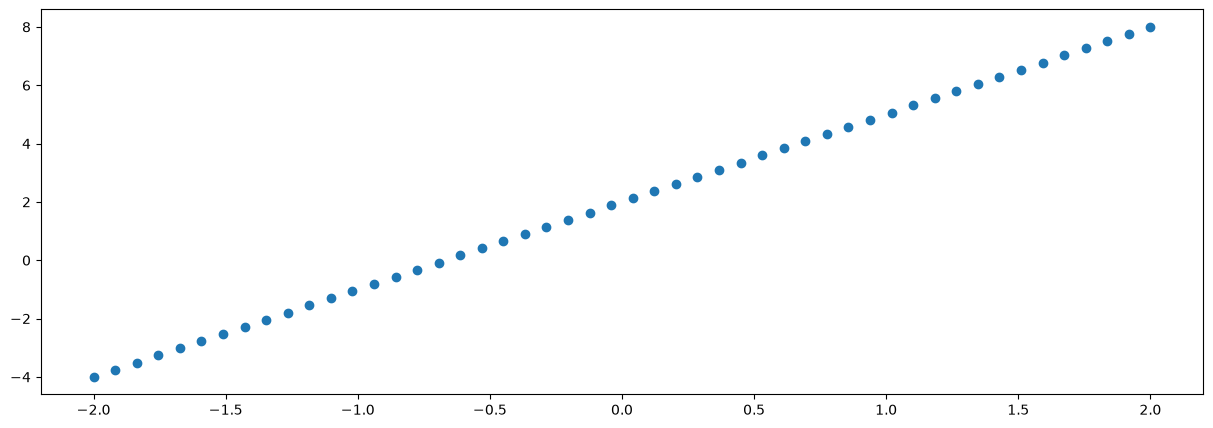

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.scatter(x.detach().numpy(), y.detach().numpy())
plt.show()



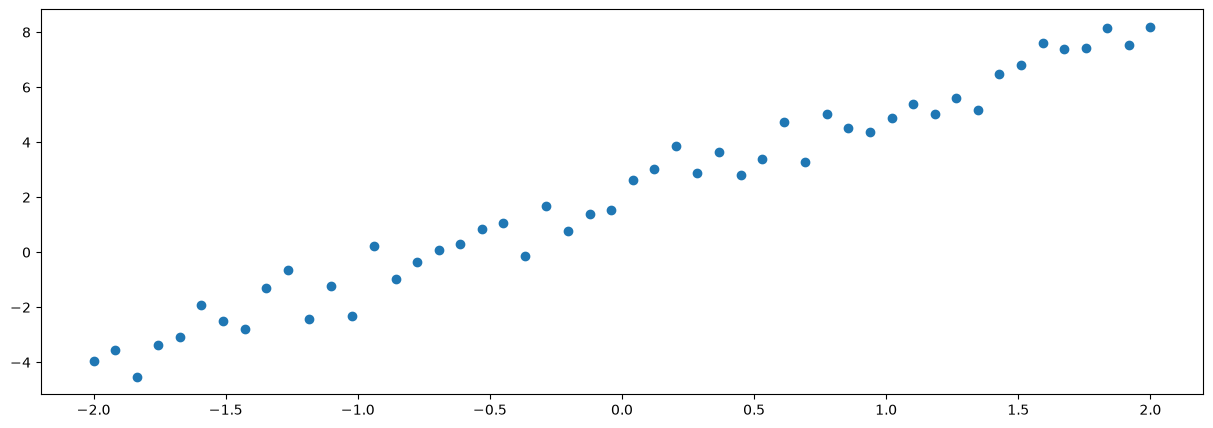

In [7]:
noise = 0.6 * torch.randn_like(x)
y = 3 * x + 2 + noise
plt.figure(figsize=(15, 5))
plt.scatter(x.detach().numpy(), y.detach().numpy())
plt.show()



In [8]:
from torch import nn

model = nn.Linear(1, 1)
model



Linear(in_features=1, out_features=1, bias=True)

In [9]:
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)



In [10]:
epochs = 500
history = []
model.train()
for epoch in range(epochs):
    optimizer.zero_grad()
    y_pred = model(x)
    loss = loss_function(y_pred, y)
    loss.backward()
    optimizer.step()
    history.append(loss.item())
    if epoch % 100 == 0:
        print(f"époque {epoch}/{epochs}  loss={loss.item()}")



époque 0/500  loss=19.5551815032959
époque 100/500  loss=9.019004821777344
époque 200/500  loss=3.6591415405273438
époque 300/500  loss=1.396693468093872
époque 400/500  loss=0.619149386882782


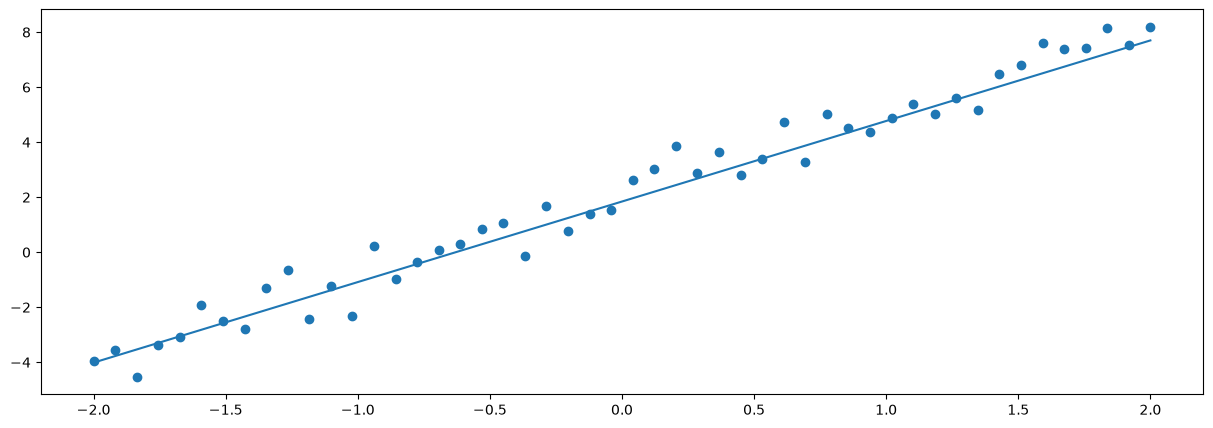

In [11]:
model.eval()
with torch.inference_mode():
    pred = model(x)

plt.figure(figsize=(15, 5))
plt.scatter(x.detach().numpy(), y.detach().numpy())
plt.plot(x.detach().numpy(), pred.numpy())
plt.show()



In [12]:
from torchmetrics.regression import R2Score

r2_score = R2Score()
r2_score.update(pred, y)
print(r2_score.compute())



tensor(0.9691)


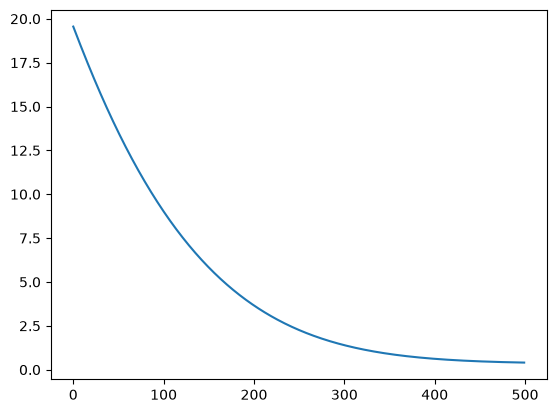

In [13]:
plt.plot(history)
plt.show()



In [14]:
mlp = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 8),
    nn.ReLU(),
    nn.Linear(8, 3),
)
mlp



Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=3, bias=True)
)

In [15]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3),
        )

    def forward(self, x):
        return self.net(x)


model = MLP()
model



MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)

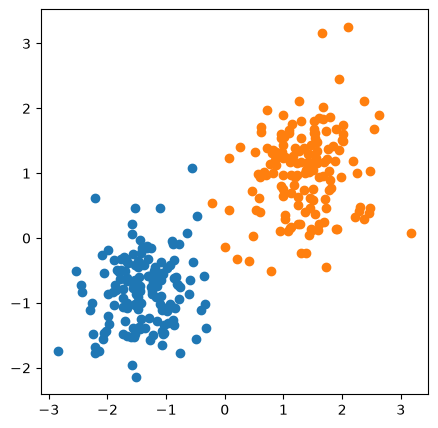

In [16]:
torch.manual_seed(0)
n = 150
c0 = torch.randn(n, 2) * 0.55 + torch.tensor([-1.4, -0.8])
c1 = torch.randn(n, 2) * 0.55 + torch.tensor([1.3, 1.0])
X = torch.cat([c0, c1])
y_cls = torch.cat([torch.zeros(n), torch.ones(n)]).long()

plt.figure(figsize=(5, 5))
plt.scatter(c0[:, 0], c0[:, 1])
plt.scatter(c1[:, 0], c1[:, 1])
plt.show()



In [17]:
clf = nn.Sequential(
    nn.Linear(2, 16),
    nn.ReLU(),
    nn.Linear(16, 16),
    nn.ReLU(),
    nn.Linear(16, 2),
)
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(clf.parameters(), lr=0.01)

history_clf = []
clf.train()
for epoch in range(200):
    opt.zero_grad()
    logits = clf(X)
    loss = loss_fn(logits, y_cls)
    loss.backward()
    opt.step()
    history_clf.append(loss.item())
    if epoch % 50 == 0:
        print(epoch, loss.item())
print(history_clf[-1])



0 0.6649941802024841
50 0.0024148342199623585
100 0.001076213433407247
150 0.0006199046620167792
0.0003834525414276868


tensor(1.)
tensor([[150,   0],
        [  0, 150]])


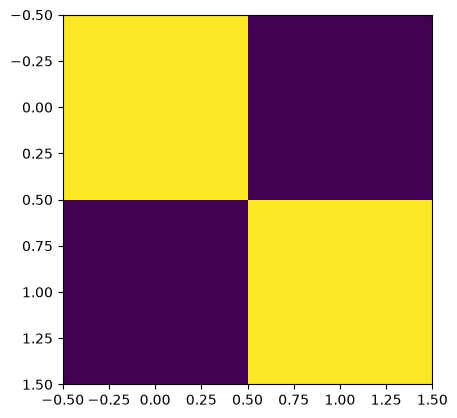

In [18]:
clf.eval()
with torch.inference_mode():
    pred_cls = clf(X).argmax(dim=1)

acc = (pred_cls == y_cls).float().mean()
print(acc)

from torchmetrics.classification import BinaryConfusionMatrix

bcm = BinaryConfusionMatrix()
cm = bcm(pred_cls, y_cls)
print(cm)
plt.imshow(cm)
plt.show()

